# Behavior and Segmentation Analysis — Steam (steam-200k)

Dataset: [Steam Video Games (Kaggle)](https://www.kaggle.com/datasets/tamber/steam-video-games)

**Columns (without header first):** `user_id`, `game_name`, `behavior_name` (`purchase` | `play`), `hours_play` (1 for `purchase`; hours `play`).

Goals:
1. Explore patterns of purchase and engagement (hours).
2. To segment games and players.
3. Co-ocorrencies discovery (association rules) in co-purchases.
4. Export CSV to use on **Power BI** (`exports/powerbi/`).

---

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import RobustScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

def resolve_data_path() -> Path:
    for base in (Path.cwd(), Path.cwd() / "Gamer Behavior", Path.cwd().parent):
        candidate = base / "data" / "steam-200k.csv"
        if candidate.exists():
            return candidate
    return Path.cwd() / "data" / "steam-200k.csv"


DATA_PATH = resolve_data_path()
NOTEBOOK_DIR = DATA_PATH.parent.parent
EXPORT_DIR = NOTEBOOK_DIR / "exports" / "powerbi"
COLUMN_NAMES = ["user_id", "game_name", "behavior_name", "hours_play"]
MIN_PLAY_HOURS = 0.0  # limiar para considerar que o usuário "jogou"

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {DATA_PATH}\n"
        "Baixe o dataset do Kaggle e salve como data/steam-200k.csv"
    )

raw = pd.read_csv(DATA_PATH, header=None)
if raw.shape[1] > len(COLUMN_NAMES):
    raw = raw.iloc[:, : len(COLUMN_NAMES)]
raw.columns = COLUMN_NAMES

raw["user_id"] = pd.to_numeric(raw["user_id"], errors="coerce").astype("Int64")
raw["game_name"] = raw["game_name"].astype(str).str.strip()
raw["behavior_name"] = raw["behavior_name"].astype(str).str.strip().str.lower()
raw["hours_play"] = pd.to_numeric(raw["hours_play"], errors="coerce")

print("Colunas:", list(raw.columns))
print("Shape:", raw.shape)
display(raw.head(10))
display(raw["behavior_name"].value_counts())

Colunas: ['user_id', 'game_name', 'behavior_name', 'hours_play']
Shape: (200000, 4)


,user_id,game_name,behavior_name,hours_play
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0
1,151603712,The Elder Scrolls V Skyrim,play,273.0
2,151603712,Fallout 4,purchase,1.0
3,151603712,Fallout 4,play,87.0
4,151603712,Spore,purchase,1.0
5,151603712,Spore,play,14.9
6,151603712,Fallout New Vegas,purchase,1.0
7,151603712,Fallout New Vegas,play,12.1
8,151603712,Left 4 Dead 2,purchase,1.0
9,151603712,Left 4 Dead 2,play,8.9


behavior_name
purchase    129511
play         70489
Name: count, dtype: int64

## 1. User aggregation × Game

In [3]:
purchases = (
    raw.loc[raw["behavior_name"] == "purchase", ["user_id", "game_name"]]
    .drop_duplicates()
    .assign(purchased=1)
)

play = (
    raw.loc[raw["behavior_name"] == "play", ["user_id", "game_name", "hours_play"]]
    .groupby(["user_id", "game_name"], as_index=False)["hours_play"]
    .sum()
    .rename(columns={"hours_play": "hours_played"})
)

user_game = purchases.merge(play, on=["user_id", "game_name"], how="outer")
user_game["purchased"] = user_game["purchased"].fillna(0).astype(int)
user_game["hours_played"] = user_game["hours_played"].fillna(0.0)
user_game["played"] = (user_game["hours_played"] > MIN_PLAY_HOURS).astype(int)

print("Pares usuário-jogo:", len(user_game))
print("Usuários:", user_game["user_id"].nunique())
print("Jogos:", user_game["game_name"].nunique())
user_game.head()

Pares usuário-jogo: 128801
Usuários: 12393
Jogos: 5153


,user_id,game_name,purchased,hours_played,played
0,5250,Alien Swarm,1,4.9,1
1,5250,Cities Skylines,1,144.0,1
2,5250,Counter-Strike,1,0.0,0
3,5250,Counter-Strike Source,1,0.0,0
4,5250,Day of Defeat,1,0.0,0


## 2. EDA — General View

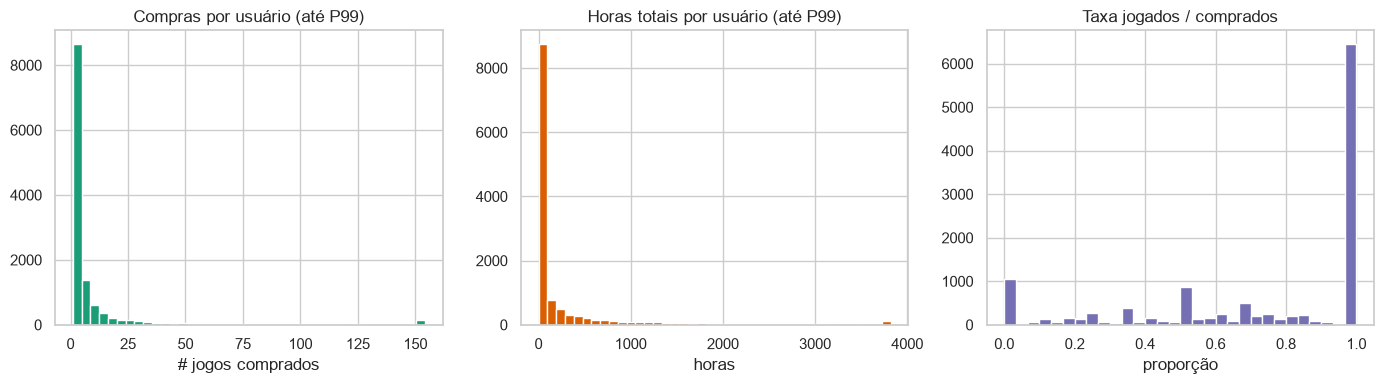

,buyers,players,total_hours
game_name,,,
Dota 2,4841,4841,981684.6
Team Fortress 2,2323,2323,173673.3
Unturned,1563,1069,16096.4
Counter-Strike Global Offensive,1412,1377,322771.6
Half-Life 2 Lost Coast,981,177,184.4
Counter-Strike Source,978,715,96075.5
Left 4 Dead 2,951,801,33596.7
Counter-Strike,856,568,134261.1
Warframe,847,424,27074.6


In [4]:
n_users = user_game["user_id"].nunique()
n_games = user_game["game_name"].nunique()
purchase_rate = user_game.groupby("user_id")["purchased"].sum()
play_depth = user_game.groupby("user_id").agg(
    total_hours=("hours_played", "sum"),
    games_played=("played", "sum"),
    games_bought=("purchased", "sum"),
)
play_depth["play_rate"] = play_depth["games_played"] / play_depth["games_bought"].replace(0, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(purchase_rate.clip(upper=purchase_rate.quantile(0.99)), bins=40, color="#1b9e77", edgecolor="white")
axes[0].set_title("Compras por usuário (até P99)")
axes[0].set_xlabel("# jogos comprados")

hours_clip = play_depth["total_hours"].clip(upper=play_depth["total_hours"].quantile(0.99))
axes[1].hist(hours_clip, bins=40, color="#d95f02", edgecolor="white")
axes[1].set_title("Horas totais por usuário (até P99)")
axes[1].set_xlabel("horas")

axes[2].hist(play_depth["play_rate"].dropna().clip(0, 1), bins=30, color="#7570b3", edgecolor="white")
axes[2].set_title("Taxa jogados / comprados")
axes[2].set_xlabel("proporção")
plt.tight_layout()
plt.show()

top_games = (
    user_game.groupby("game_name")
    .agg(buyers=("purchased", "sum"), players=("played", "sum"), total_hours=("hours_played", "sum"))
    .sort_values("buyers", ascending=False)
)
display(top_games.head(15))

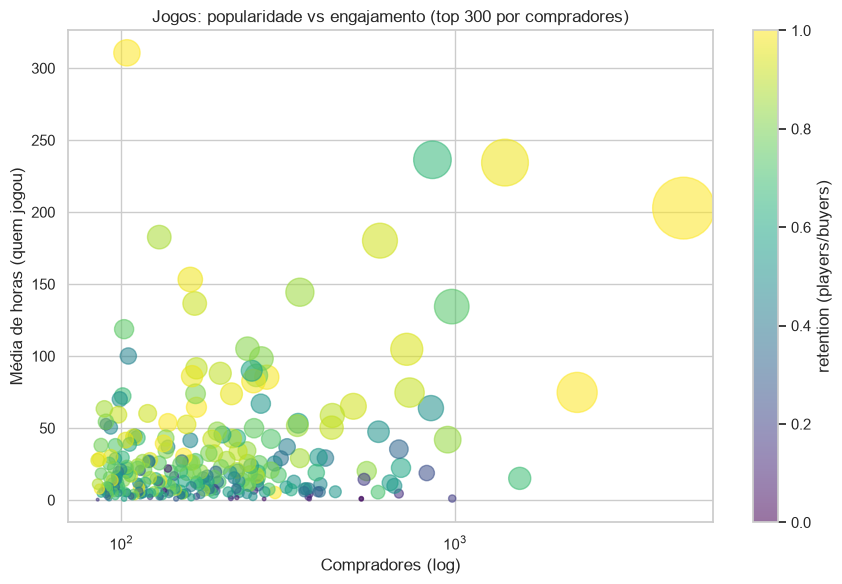

In [5]:
game_stats = user_game.groupby("game_name").agg(
    buyers=("purchased", "sum"),
    players=("played", "sum"),
    total_hours=("hours_played", "sum"),
)
played_only = user_game.loc[user_game["played"] == 1].groupby("game_name")["hours_played"]
game_stats["avg_hours_per_player"] = played_only.mean()
game_stats["retention"] = game_stats["players"] / game_stats["buyers"].replace(0, np.nan)
game_stats = game_stats.sort_values("buyers", ascending=False)

scatter = game_stats.nlargest(300, "buyers").copy()
plt.figure(figsize=(9, 6))
plt.scatter(
    scatter["buyers"],
    scatter["avg_hours_per_player"].fillna(0),
    s=np.sqrt(scatter["total_hours"]) * 2,
    alpha=0.55,
    c=scatter["retention"].fillna(0),
    cmap="viridis",
)
plt.xscale("log")
plt.xlabel("Compradores (log)")
plt.ylabel("Média de horas (quem jogou)")
plt.title("Jogos: popularidade vs engajamento (top 300 por compradores)")
plt.colorbar(label="retention (players/buyers)")
plt.tight_layout()
plt.show()

## 3. Features per user

In [6]:
def build_user_features(ug: pd.DataFrame) -> pd.DataFrame:
    g = ug.groupby("user_id")
    feats = g.agg(
        n_purchases=("purchased", "sum"),
        n_played=("played", "sum"),
        total_hours=("hours_played", "sum"),
        max_hours=("hours_played", "max"),
    )
    feats["avg_hours_played_game"] = np.where(
        feats["n_played"] > 0, feats["total_hours"] / feats["n_played"], 0.0
    )
    feats["play_purchase_ratio"] = np.where(
        feats["n_purchases"] > 0, feats["n_played"] / feats["n_purchases"], np.nan
    )
    feats["share_top_game_hours"] = np.where(
        feats["total_hours"] > 0, feats["max_hours"] / feats["total_hours"], 0.0
    )
    return feats


user_feats = build_user_features(user_game)
display(user_feats.describe().T)

,count,mean,std,min,25%,50%,75%,max
n_purchases,12393.0,10.393044,35.635078,1.0,1.0,2.0,6.0,1068.0
n_played,12393.0,5.686597,17.077253,0.0,1.0,1.0,3.0,498.0
total_hours,12393.0,278.009021,760.270618,0.0,1.3,13.5,155.6,11754.0
max_hours,12393.0,176.163568,504.764677,0.0,1.2,11.6,107.0,11754.0
avg_hours_played_game,12393.0,74.324538,283.750407,0.0,1.1,7.9,39.0,11754.0
play_purchase_ratio,12393.0,0.726836,0.344795,0.0,0.5,1.0,1.0,1.0
share_top_game_hours,12393.0,0.780062,0.329174,0.0,0.6,1.0,1.0,1.0


## 4. Segmentation (rules)

In [7]:
def segment_users_rules(df: pd.DataFrame) -> pd.Series:
    q = {
        "hours_hi": df["total_hours"].quantile(0.75),
        "hours_lo": df["total_hours"].quantile(0.25),
        "buy_hi": df["n_purchases"].quantile(0.75),
        "buy_lo": df["n_purchases"].quantile(0.25),
        "play_ratio_lo": df["play_purchase_ratio"].quantile(0.25),
        "specialist": df["share_top_game_hours"].quantile(0.75),
    }
    seg = pd.Series("Generalista", index=df.index, dtype="object")
    seg.loc[(df["n_purchases"] >= q["buy_hi"]) & (df["play_purchase_ratio"] <= q["play_ratio_lo"])] = "Colecionador"
    seg.loc[(df["total_hours"] >= q["hours_hi"]) & (df["n_played"] >= df["n_played"].quantile(0.75))] = "Hardcore"
    seg.loc[(df["total_hours"] <= q["hours_lo"]) & (df["n_purchases"] <= q["buy_lo"])] = "Casual"
    seg.loc[df["share_top_game_hours"] >= q["specialist"]] = "Especialista"
    return seg


user_feats["segment_rule"] = segment_users_rules(user_feats)
seg_counts = user_feats["segment_rule"].value_counts()
print(seg_counts)
print("\n% do total:")
print((seg_counts / len(user_feats) * 100).round(1))

persona = user_feats.groupby("segment_rule").mean(numeric_only=True)
display(persona[["n_purchases", "n_played", "total_hours", "play_purchase_ratio", "share_top_game_hours"]])

segment_rule
Especialista    6559
Generalista     2540
Hardcore        2121
Colecionador     600
Casual           573
Name: count, dtype: int64

% do total:
segment_rule
Especialista    52.9
Generalista     20.5
Hardcore        17.1
Colecionador     4.8
Casual           4.6
Name: count, dtype: float64


,n_purchases,n_played,total_hours,play_purchase_ratio,share_top_game_hours
segment_rule,,,,,
Casual,1.000000,0.000000,0.000000,0.000000,0.000000
Colecionador,13.226667,3.326667,125.967500,0.267184,0.594721
Especialista,1.721147,1.000000,85.514316,0.854458,1.000000
Generalista,4.873228,3.413780,104.236299,0.712481,0.623909
Hardcore,45.556341,25.105139,1199.498680,0.675756,0.550093


## 5. Clustering (K-Means)

In [8]:
cluster_cols = [
    "n_purchases",
    "n_played",
    "total_hours",
    "avg_hours_played_game",
    "share_top_game_hours",
]
X = user_feats[cluster_cols].copy()
X["total_hours"] = np.log1p(X["total_hours"])
X["avg_hours_played_game"] = np.log1p(X["avg_hours_played_game"])
X = X.replace([np.inf, -np.inf], np.nan).dropna()

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

ks = range(3, 9)
scores = {}
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)
print("Silhouette por k:", {k: round(v, 3) for k, v in scores.items()})

best_k = max(scores, key=scores.get)
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
user_feats.loc[X.index, "cluster_kmeans"] = kmeans.fit_predict(X_scaled)

cluster_profile = user_feats.groupby("cluster_kmeans")[cluster_cols].mean()
display(cluster_profile)

Silhouette por k: {3: 0.881, 4: 0.804, 5: 0.764, 6: 0.759, 7: 0.705, 8: 0.656}


,n_purchases,n_played,total_hours,avg_hours_played_game,share_top_game_hours
cluster_kmeans,,,,,
0.0,5.151918,2.98999,206.208185,76.080919,0.799800
1.0,102.604857,56.90287,1816.069095,34.475454,0.329450
2.0,405.288462,176.00000,3293.915385,19.935837,0.193235


## 6. Games segmentation (popularity × retention)

In [9]:
gs = game_stats.copy()
gs["pop_tier"] = pd.qcut(gs["buyers"].rank(method="first"), q=3, labels=["Baixa", "Média", "Alta"])
gs["eng_tier"] = pd.qcut(
    gs["avg_hours_per_player"].fillna(0).rank(method="first"), q=3, labels=["Baixo", "Médio", "Alto"]
)
gs["game_segment"] = gs["pop_tier"].astype(str) + " pop / " + gs["eng_tier"].astype(str) + " eng"

merged = user_game.merge(user_feats[["segment_rule"]], left_on="user_id", right_index=True)
merged = merged.merge(gs[["game_segment"]], left_on="game_name", right_index=True)
persona_game = (
    merged.groupby(["segment_rule", "game_segment"])["hours_played"]
    .sum()
    .unstack(fill_value=0)
)
display(persona_game)

game_segment,Alta pop / Alto eng,Alta pop / Baixo eng,Alta pop / Médio eng,Baixa pop / Alto eng,Baixa pop / Baixo eng,Baixa pop / Médio eng,Média pop / Alto eng,Média pop / Baixo eng,Média pop / Médio eng
segment_rule,,,,,,,,,
Casual,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Colecionador,74774.7,0.9,350.6,177.5,0.6,22.0,206.1,0.5,47.6
Especialista,556446.4,0.1,502.4,475.9,0.0,18.8,3398.2,0.7,45.9
Generalista,259450.2,3.3,2217.3,445.3,1.1,75.1,2369.9,3.6,194.4
Hardcore,2477898.7,11.5,17182.8,8429.1,11.4,801.1,36664.0,12.3,3125.8


## 7. Patterns — Association Rules (co-purchase)

In [10]:
try:
    from mlxtend.frequent_patterns import apriori, association_rules
    from mlxtend.preprocessing import TransactionEncoder
except ImportError:
    raise ImportError("Instale mlxtend: pip install mlxtend")

baskets = (
    user_game.loc[user_game["purchased"] == 1]
    .groupby("user_id")["game_name"]
    .apply(list)
)
# Filtra usuários com biblioteca grande o suficiente para regras estáveis
baskets = baskets[baskets.str.len() >= 3]

top_n_games = user_game.groupby("game_name")["purchased"].sum().nlargest(80).index
baskets_filtered = baskets.apply(lambda games: [g for g in games if g in top_n_games])
baskets_filtered = baskets_filtered[baskets_filtered.str.len() >= 2]

te = TransactionEncoder()
te_ary = te.fit(baskets_filtered.tolist()).transform(baskets_filtered.tolist())
basket_df = pd.DataFrame(te_ary, columns=te.columns_)

freq = apriori(basket_df, min_support=0.02, use_colnames=True)
rules = association_rules(freq, metric="lift", min_threshold=1.2)
rules = rules.sort_values("lift", ascending=False)
display(rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(15))

,antecedents,consequents,support,confidence,lift
20648318,"frozenset({Deathmatch Classic, Half-Life, Day ...","frozenset({Counter-Strike, Half-Life 2 Deathma...",0.020652,1.000000,46.860215
20648316,"frozenset({Deathmatch Classic, Half-Life, Day ...","frozenset({Counter-Strike, Half-Life 2 Deathma...",0.020652,1.000000,46.860215
13780112,"frozenset({Half-Life, Day of Defeat, Counter-S...","frozenset({Counter-Strike Condition Zero, Deat...",0.020652,1.000000,46.860215
13780109,"frozenset({Half-Life, Day of Defeat, Counter-S...","frozenset({Deathmatch Classic, Team Fortress C...",0.020652,1.000000,46.860215
13780107,"frozenset({Half-Life, Day of Defeat, Counter-S...","frozenset({Deathmatch Classic, Counter-Strike ...",0.020652,1.000000,46.860215
13780103,"frozenset({Half-Life, Day of Defeat, Counter-S...","frozenset({Deathmatch Classic, Half-Life Blue ...",0.020652,1.000000,46.860215
13778458,"frozenset({Deathmatch Classic, Half-Life Blue ...","frozenset({Half-Life, Day of Defeat, Counter-S...",0.020652,0.967742,46.860215
13778455,"frozenset({Deathmatch Classic, Half-Life Oppos...","frozenset({Half-Life, Day of Defeat, Counter-S...",0.020652,0.967742,46.860215
13778451,"frozenset({Deathmatch Classic, Counter-Strike ...","frozenset({Half-Life, Day of Defeat, Counter-S...",0.020652,0.967742,46.860215
13778449,"frozenset({Deathmatch Classic, Counter-Strike ...","frozenset({Half-Life, Day of Defeat, Counter-S...",0.020652,0.967742,46.860215


## 8. Power Bi Export

CVS's `exports/powerbi/` to star schema on Power BI:

| File | Type | Relationship |
|---------|------|----------------|
| `fact_user_game.csv` | Fato | `user_id`, `game_name` |
| `dim_user.csv` | Dimensão jogador | `user_id` |
| `dim_game.csv` | Dimensão jogo | `game_name` |
| `fact_persona_game_matrix.csv` | Fato agregado | personas × segmento de jogo |
| `fact_association_rules.csv` | Opcional | regras de co-compra (lift) |

In [11]:
def frozenset_to_str(item) -> str:
    if hasattr(item, "__iter__") and not isinstance(item, str):
        return ", ".join(sorted(str(x) for x in item))
    return str(item)


def export_for_power_bi() -> dict[str, Path]:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    written: dict[str, Path] = {}

    dim_user = user_feats.reset_index()
    dim_game = gs.reset_index()

    user_cols = ["segment_rule", "cluster_kmeans"]
    user_cols = [c for c in user_cols if c in user_feats.columns]
    game_cols = ["game_segment", "pop_tier", "eng_tier"]
    game_cols = [c for c in game_cols if c in gs.columns]

    fact_user_game = user_game.copy()
    if user_cols:
        fact_user_game = fact_user_game.merge(
            user_feats[user_cols],
            left_on="user_id",
            right_index=True,
            how="left",
        )
    if game_cols:
        fact_user_game = fact_user_game.merge(
            gs[game_cols],
            left_on="game_name",
            right_index=True,
            how="left",
        )

    persona_long = (
        merged.groupby(["segment_rule", "game_segment"], as_index=False)
        .agg(
            total_hours=("hours_played", "sum"),
            interactions=("hours_played", "count"),
            unique_users=("user_id", "nunique"),
        )
    )

    paths = {
        "fact_user_game": EXPORT_DIR / "fact_user_game.csv",
        "dim_user": EXPORT_DIR / "dim_user.csv",
        "dim_game": EXPORT_DIR / "dim_game.csv",
        "fact_persona_game_matrix": EXPORT_DIR / "fact_persona_game_matrix.csv",
    }
    fact_user_game.to_csv(paths["fact_user_game"], index=False, encoding="utf-8-sig")
    dim_user.to_csv(paths["dim_user"], index=False, encoding="utf-8-sig")
    dim_game.to_csv(paths["dim_game"], index=False, encoding="utf-8-sig")
    persona_long.to_csv(paths["fact_persona_game_matrix"], index=False, encoding="utf-8-sig")
    written.update(paths)

    rules_df = globals().get("rules")
    if rules_df is not None and len(rules_df) > 0:
        rules_export = rules_df.copy()
        rules_export["antecedents_str"] = rules_export["antecedents"].map(frozenset_to_str)
        rules_export["consequents_str"] = rules_export["consequents"].map(frozenset_to_str)
        out_cols = [
            "antecedents_str",
            "consequents_str",
            "support",
            "confidence",
            "lift",
            "leverage",
            "conviction",
        ]
        out_cols = [c for c in out_cols if c in rules_export.columns]
        rules_path = EXPORT_DIR / "fact_association_rules.csv"
        rules_export[out_cols].to_csv(rules_path, index=False, encoding="utf-8-sig")
        written["fact_association_rules"] = rules_path

    readme = EXPORT_DIR / "README_powerbi.txt"
    readme.write_text(
        "Modelo sugerido:\n"
        "  dim_user[user_id] -> fact_user_game[user_id]\n"
        "  dim_game[game_name] -> fact_user_game[game_name]\n"
        "Encoding: UTF-8 com BOM (utf-8-sig) para Excel/Power BI.\n",
        encoding="utf-8",
    )
    written["readme"] = readme

    return written


exported = export_for_power_bi()
print("Arquivos gerados em:", EXPORT_DIR.resolve())
for name, path in exported.items():
    size_kb = path.stat().st_size / 1024
    print(f"  {name}: {path.name} ({size_kb:.1f} KB)")

Arquivos gerados em: C:\Users\anara\Desktop\Game Analysis\Gamer Behavior\exports\powerbi
  fact_user_game: fact_user_game.csv (10594.0 KB)
  dim_user: dim_user.csv (805.2 KB)
  dim_game: dim_game.csv (423.9 KB)
  fact_persona_game_matrix: fact_persona_game_matrix.csv (2.1 KB)
  fact_association_rules: fact_association_rules.csv (5998216.0 KB)
  readme: README_powerbi.txt (0.2 KB)
